# Topic 21a - Anatomy of a chart

Every matplotlib chart - every one you will build in this entire topic - is built from the same two kinds of object. This notebook makes that model explicit, then uses it to build multi-panel figures and save them to disk, both of which the rest of Topic 21 assumes you can already do.

Work through it after reading section 1 of the [main lesson](topic21_data_visualization.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## Figure and Axes

A **Figure** is the whole canvas - the thing you save to a PNG. An **Axes** is one plot on that canvas, with its own x-axis, y-axis, title, and data. Most of the charts you have seen in other courses were built with `plt.bar(...)` or `plt.plot(...)` directly - that is a shortcut that quietly creates a Figure with one Axes for you. This course always creates both explicitly, because the shortcut stops working the moment you want more than one chart on a page.

<class 'matplotlib.figure.Figure'>
<class 'matplotlib.axes._axes.Axes'>


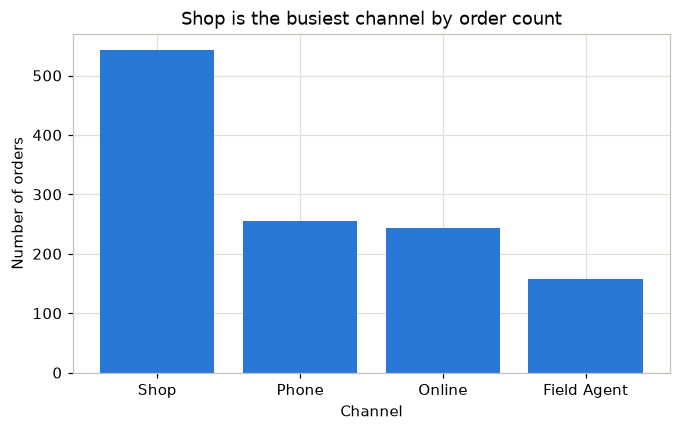

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
print(type(fig))
print(type(ax))

orders_by_channel = analysis["channel"].value_counts()
ax.bar(orders_by_channel.index, orders_by_channel.values, color=PALETTE["blue"])
ax.set_title("Shop is the busiest channel by order count")
ax.set_xlabel("Channel")
ax.set_ylabel("Number of orders")
plt.show()

`figsize=(7, 4)` is in **inches**, not pixels - it matters when you save the figure, because the pixel count is `figsize * dpi`. The default `dpi` in this course is set once, in the setup cell (`plt.rcParams["figure.dpi"]`), so every chart in a notebook renders at a consistent size without repeating it.

---

## Several Axes on one Figure

`plt.subplots(rows, cols)` returns one Figure and an **array** of Axes. The shape of that array depends on `rows` and `cols`, and this is the single most common beginner error in matplotlib: with one row, `axes` is a 1-D array and you index it `axes[1]`; with more than one row, it is 2-D and you index it `axes[1, 0]`. Mixing the two raises an `IndexError` that gives no hint about which assumption was wrong.

1 row: <class 'numpy.ndarray'> (2,)


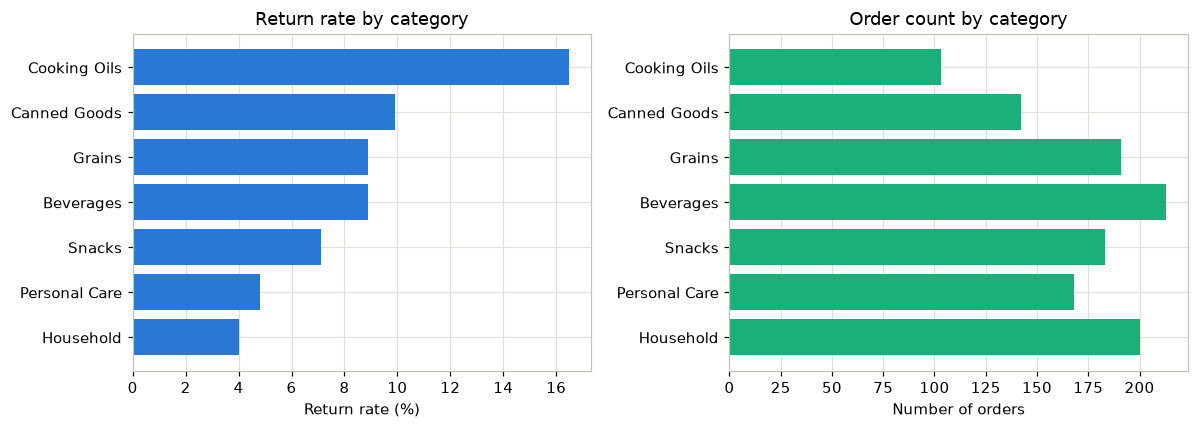

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
print("1 row:", type(axes), axes.shape)   # 1-D - axes[0], axes[1]

return_rate = (analysis.groupby("category")["was_returned"].mean() * 100).round(1).sort_values()
axes[0].barh(return_rate.index, return_rate.values, color=PALETTE["blue"])
axes[0].set_title("Return rate by category")
axes[0].set_xlabel("Return rate (%)")

order_count = analysis["category"].value_counts().reindex(return_rate.index)
axes[1].barh(order_count.index, order_count.values, color=PALETTE["aqua"])
axes[1].set_title("Order count by category")
axes[1].set_xlabel("Number of orders")

fig.tight_layout()
plt.show()

2 rows: <class 'numpy.ndarray'> (2, 2)


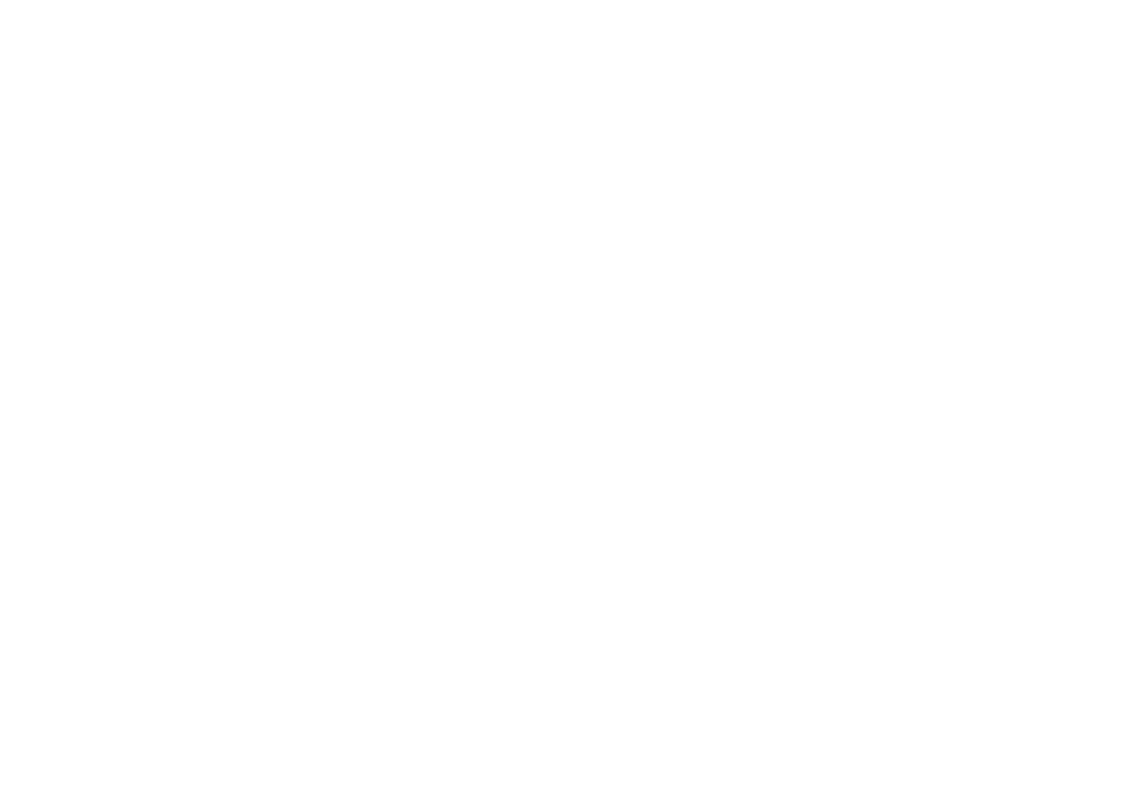

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
print("2 rows:", type(axes), axes.shape)  # 2-D - axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

for ax in axes.flat:        # .flat gives you a 1-D view when you just need "every panel"
    ax.set_visible(False)   # placeholders - real panels go in the "put it together" sections

plt.show()

That second cell is why the main lesson's dashboard loops with `axes[0, 0]`, `axes[0, 1]`, `axes[1, 0]`, `axes[1, 1]` by name rather than a loop - with only four panels and four different chart types, explicit indexing is more readable than a loop would be. `axes.flat` is the tool for when you genuinely want to do the *same* thing to every panel.

---

## Cleaning up the chrome

A default matplotlib Axes draws a box on all four sides and heavy-ish gridlines. Removing the top and right spines, and keeping gridlines thin and behind the data (`axes.axisbelow`, set once in this course's setup cell), reduces visual noise without losing any information - the data was never near the top or right edge anyway.

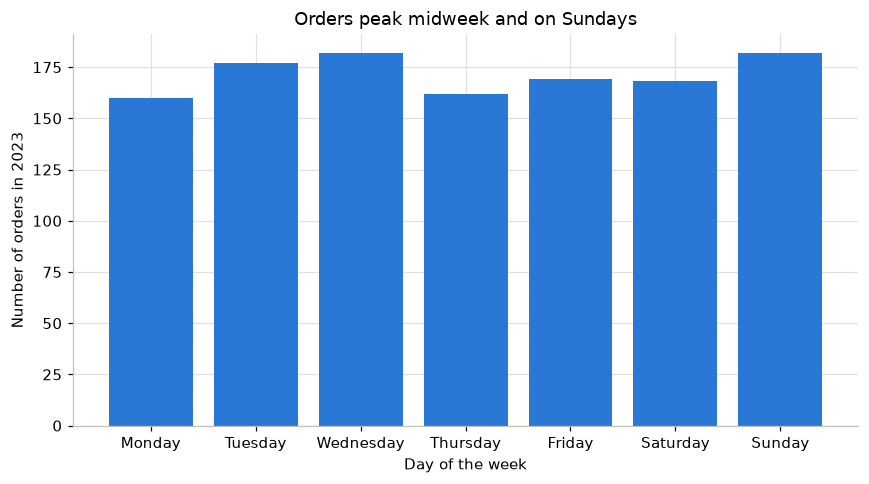

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
orders_by_weekday = analysis["weekday"].value_counts().reindex(weekday_order)
ax.bar(orders_by_weekday.index, orders_by_weekday.values, color=PALETTE["blue"])

ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Orders peak midweek and on Sundays")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Number of orders in 2023")

fig.tight_layout()
plt.show()

### Try It 1 - a labelled, two-panel figure

Build one Figure with two Axes side by side (`plt.subplots(1, 2, ...)`):

- left panel: a bar chart of total revenue by segment (`Retail`, `Wholesale`, `Institution`);
- right panel: a bar chart of number of orders by segment;
- both panels need a title that states what the chart shows, an x-axis label, and a y-axis label with units;
- remove the top and right spines on both panels.

Does the segment with the most orders also have the most revenue? Say so in a comment.

In [7]:
# YOUR CODE HERE

---

## Saving a figure

`fig.savefig(...)` - never `plt.savefig(...)` once you are working with named Figures, for the same reason you address `ax` by name instead of relying on "whatever was drawn last." Call it **before** `plt.show()` - in some environments `plt.show()` clears the figure from memory, and a save after that point writes a blank image.

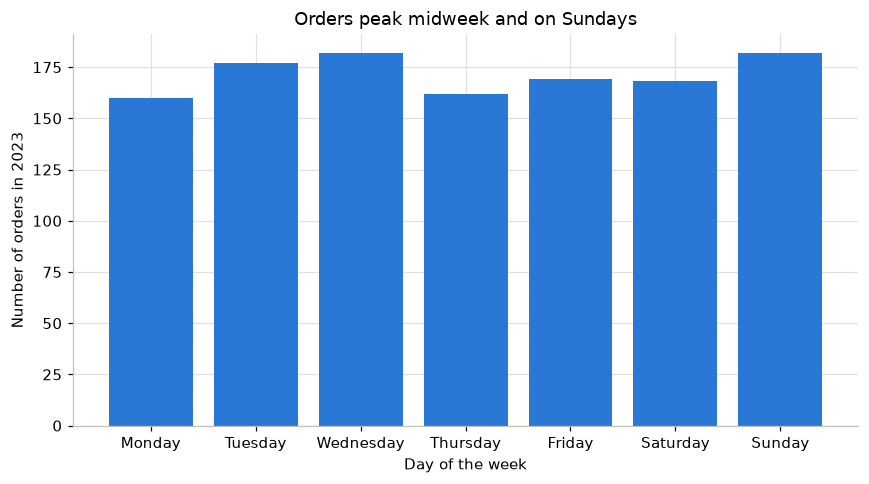

Saved to charts/orders_by_weekday.png


In [8]:
charts_dir = Path("charts")
charts_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(orders_by_weekday.index, orders_by_weekday.values, color=PALETTE["blue"])
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Orders peak midweek and on Sundays")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Number of orders in 2023")
fig.tight_layout()

fig.savefig(charts_dir / "orders_by_weekday.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved to {charts_dir / 'orders_by_weekday.png'}")

`dpi=150` is a reasonable default for a chart that will be viewed on screen or embedded in a README; use `dpi=300` for anything headed to print. `bbox_inches="tight"` trims the whitespace matplotlib otherwise leaves around the figure - without it, rotated tick labels are often clipped at the saved image's edge even though they looked fine in the notebook.

---
## Where this fits

- [Back to the main lesson](topic21_data_visualization.ipynb)
- Previous: [Main lesson](topic21_data_visualization.ipynb)
- Next: [21b - Comparing categories](topic21b_comparing_categories.ipynb)